# Charging Desert Analysis Notebook

In [3]:
import sys 
from pathlib import Path 
import geopandas as gpd
import matplotlib.pyplot as plt 
import seaborn as sns

## Load metric and scored tract layers

In [4]:
PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT / "src"))
from config import GEOJSON_DIR, PROCESSED_DIR , CRS_WEB

deserts_gdf = gpd.read_file(GEOJSON_DIR / "charging_deserts.geojson")

metrics_gdf = gpd.read_parquet(PROCESSED_DIR / "tract_coverage_metrics.parquet")

print(f"Loaded {len(deserts_gdf)} tracts with CRS: {deserts_gdf.crs}")
deserts_gdf.head()

Loaded 9129 tracts with CRS: EPSG:4326


,GEOID,total_population,median_income,tract_area_sq_km,population_density,missing_population_flag,zero_population_flag,ev_station_count,level2_ports,dcfc_ports,...,ports_per_sq_km,ports_per_1000,dcfc_per_1000,comp_gas_access,comp_pop_density,comp_ev_gap,comp_dcfc_distance,desert_score,severity_score,geometry
0,06001442700,3068,209625,1.234016,2486.192141,False,False,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.416667,0.033726,1.000000,0.009662,46.40,adequate,"POLYGON ((-122.01721 37.53932, -122.01719 37.5..."
1,06001442800,3041,179844,1.278647,2378.294609,False,False,2.0,2.0,5.0,...,5.474535,2.301874,1.644196,0.375000,0.032263,0.995119,0.005954,45.10,adequate,"POLYGON ((-122.00230 37.52984, -122.00224 37.5..."
2,06037204920,2274,75972,0.909975,2498.968949,False,False,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.250000,0.033900,1.000000,0.017414,42.36,adequate,"POLYGON ((-118.20284 34.01966, -118.20283 34.0..."
3,06037205110,3501,54939,0.286961,12200.274505,False,False,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.416667,0.165502,1.000000,0.017993,49.82,adequate,"POLYGON ((-118.21963 34.02629, -118.21945 34.0..."
4,06037205120,3252,32406,1.466240,2217.917682,False,False,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.458333,0.030087,1.000000,0.013285,47.41,adequate,"POLYGON ((-118.22023 34.02056, -118.22018 34.0..."


## Score distribution

In [5]:
# Descriptive statistics for desert scores
deserts_gdf["desert_score"].describe()

count    9129.000000
mean       42.781615
std         5.429677
min        14.740000
25%        38.140000
50%        42.280000
75%        46.390000
max        72.540000
Name: desert_score, dtype: float64

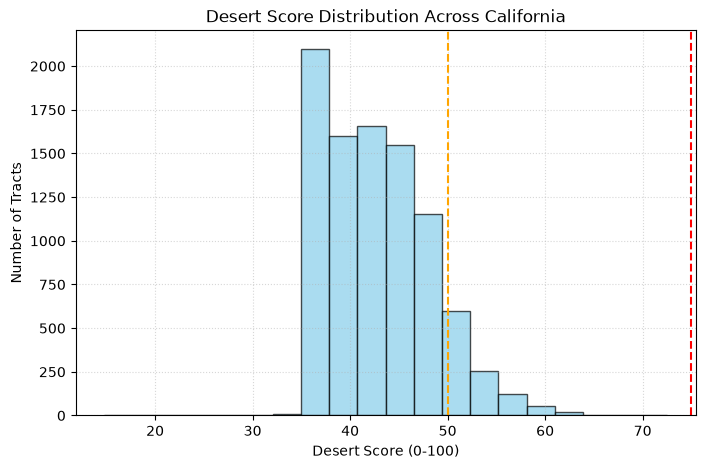

In [6]:
# Histogram of score values
x = deserts_gdf['desert_score']
plt.figure(figsize=(8,5))
plt.hist(x, color='skyblue', edgecolor='black', bins=20, alpha=0.7)
plt.axvline(50, color='orange', linestyle='--', label='Moderate (50)')
plt.axvline(75, color='red', linestyle='--', label='Severe (75)')
plt.xlabel('Desert Score (0-100)')
plt.ylabel('Number of Tracts')
plt.title("Desert Score Distribution Across California")
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()


In [7]:
# Count tracts by severity class
deserts_gdf['desert_score'].value_counts()

desert_score
36.73    19
35.75    19
35.67    18
35.73    18
35.66    18
         ..
52.20     1
53.69     1
60.38     1
58.06     1
56.41     1
Name: count, Length: 2032, dtype: int64

## Component Interpretation

In [9]:
# Summary statistics of components
component_cols = [
    'comp_gas_access',
    'comp_pop_density',
    'comp_ev_gap',
    'comp_dcfc_distance'
]

deserts_gdf[component_cols].describe().round(3)

,comp_gas_access,comp_pop_density,comp_ev_gap,comp_dcfc_distance
count,9129.000,9129.000,9129.000,9129.000
mean,0.256,0.044,0.995,0.029
std,0.200,0.052,0.023,0.049
min,0.000,0.000,0.000,0.000
25%,0.083,0.013,0.998,0.009
50%,0.250,0.033,1.000,0.016
75%,0.375,0.056,1.000,0.027
max,1.000,1.000,1.000,1.000


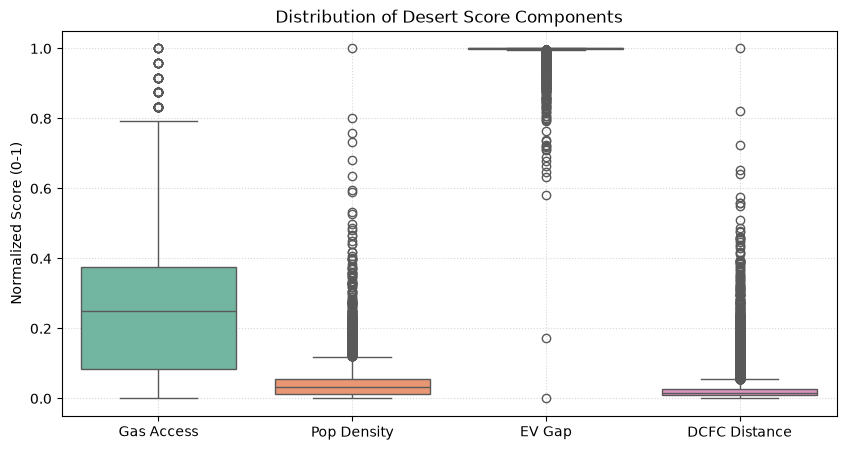

In [10]:
# Box plots of distributions
plt.figure(figsize=(10,5))
sns.boxplot(data=deserts_gdf[component_cols], palette='Set2')
plt.xticks(
    ticks=range(4),
    labels=['Gas Access', 'Pop Density', 'EV Gap', 'DCFC Distance']
)
plt.ylabel("Normalized Score (0-1)")
plt.title("Distribution of Desert Score Components")
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

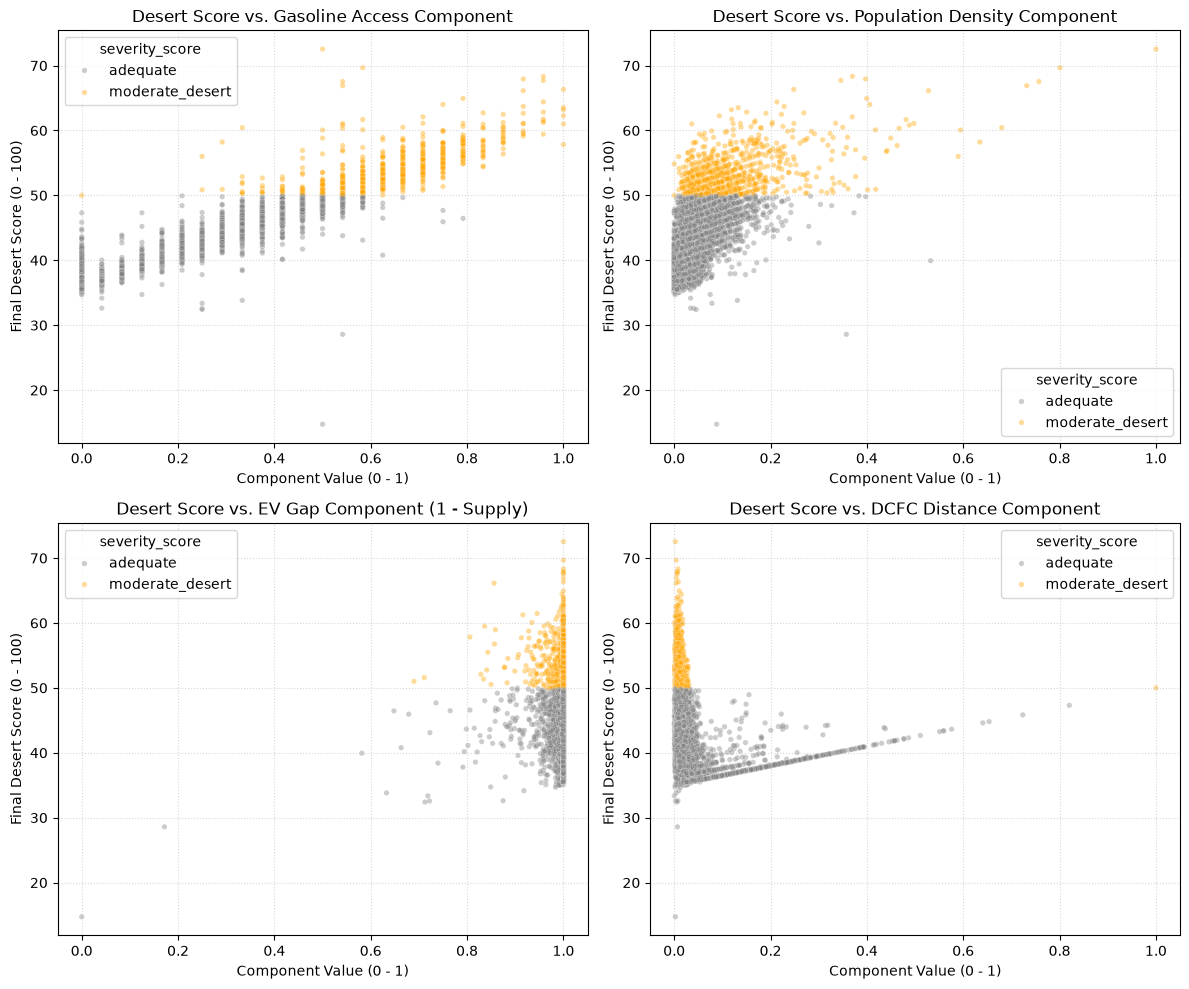

In [11]:
# Create a 2x2 subplot layout for the 4 component scatter plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

components = [
    ('comp_gas_access', 'Gasoline Access Component', axes[0, 0]),
    ('comp_pop_density', 'Population Density Component', axes[0, 1]),
    ('comp_ev_gap', 'EV Gap Component (1 - Supply)', axes[1, 0]),
    ('comp_dcfc_distance', 'DCFC Distance Component', axes[1, 1])
]

for col, title, ax in components:
    sns.scatterplot(
        data=deserts_gdf, 
        x=col, 
        y='desert_score', 
        hue='severity_score', 
        palette={'adequate': 'gray', 'moderate_desert': 'orange', 'severe_desert': 'red'},
        alpha=0.4, 
        s=15,
        ax=ax
    )
    ax.set_title(f'Desert Score vs. {title}')
    ax.set_xlabel('Component Value (0 - 1)')
    ax.set_ylabel('Final Desert Score (0 - 100)')
    ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


## Map outputs

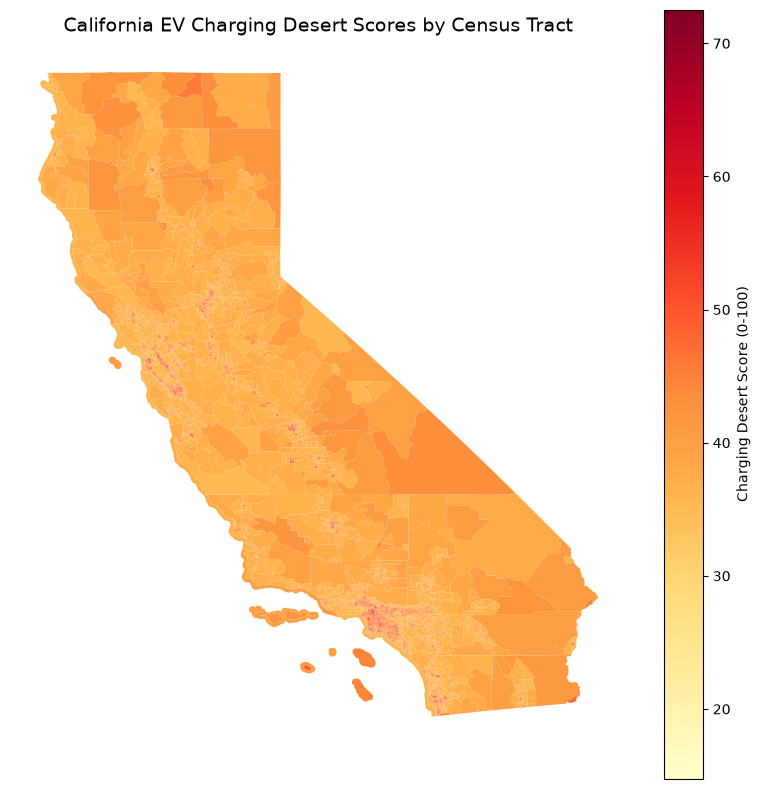

In [28]:
# Choropleth of desert score
import matplotlib.pyplot as plt 

fig, ax = plt.subplots(1,1, figsize=(8,8))

deserts_gdf.plot(
    column='desert_score',
    cmap="YlOrRd",
    legend=True,
    legend_kwds={'label': 'Charging Desert Score (0-100)', 'orientation': 'vertical'},
    ax=ax,
    edgecolor='none'
)
ax.set_title("California EV Charging Desert Scores by Census Tract", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
plt.show()

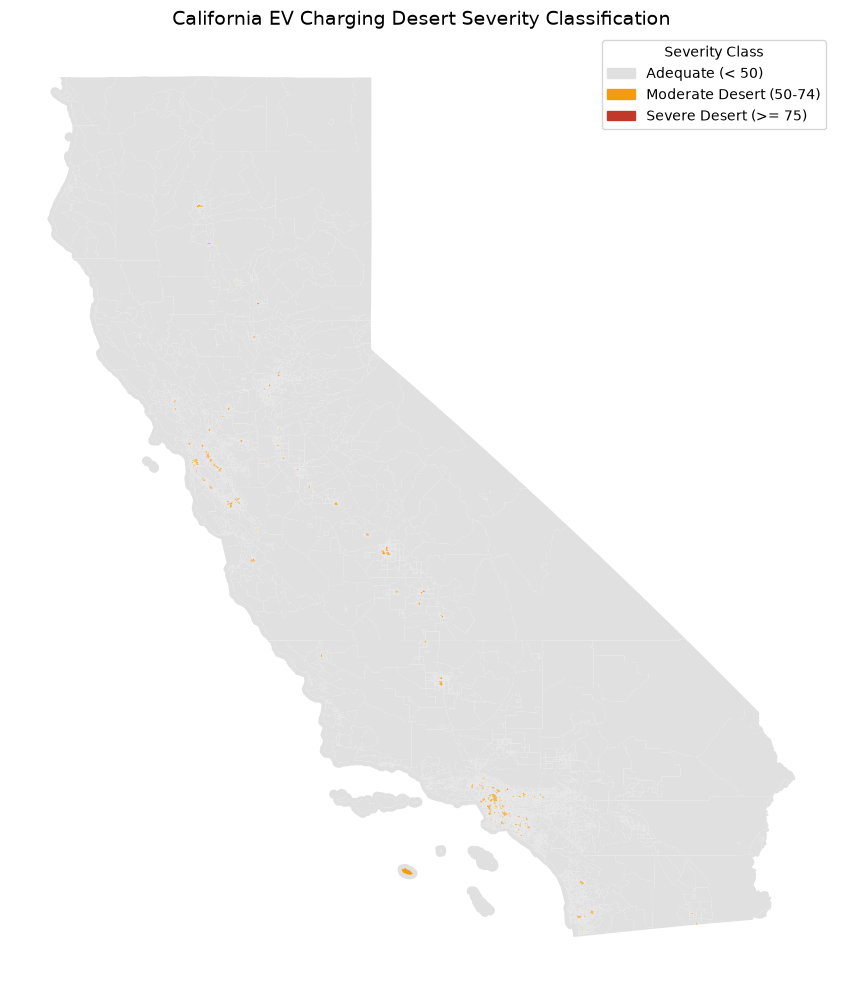

In [27]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Custom color mapping for severity classes
color_dict = {
    "adequate": "#e0e0e0",         # Light gray
    "moderate_desert": "#f39c12",   # Orange
    "severe_desert": "#c0392b"      # Dark Red
}

deserts_gdf.plot(
    color=deserts_gdf["severity_score"].map(color_dict),
    ax=ax,
    edgecolor="none"
)

# Build custom legend handles
legend_handles = [
    mpatches.Patch(color="#e0e0e0", label="Adequate (< 50)"),
    mpatches.Patch(color="#f39c12", label="Moderate Desert (50-74)"),
    mpatches.Patch(color="#c0392b", label="Severe Desert (>= 75)")
]

ax.legend(handles=legend_handles, loc="upper right", title="Severity Class", frameon=True)
ax.set_title("California EV Charging Desert Severity Classification", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
plt.show()


In [16]:
# Inspect top 15 severe tracts
top_15 = deserts_gdf['desert_score'].value_counts(ascending=False).head(15)
top_15


desert_score
36.73    19
35.75    19
35.67    18
35.73    18
35.66    18
35.56    18
35.89    16
35.79    16
35.63    16
35.88    16
35.52    15
36.02    15
35.59    15
35.81    15
35.54    15
Name: count, dtype: int64

## Demographic Context

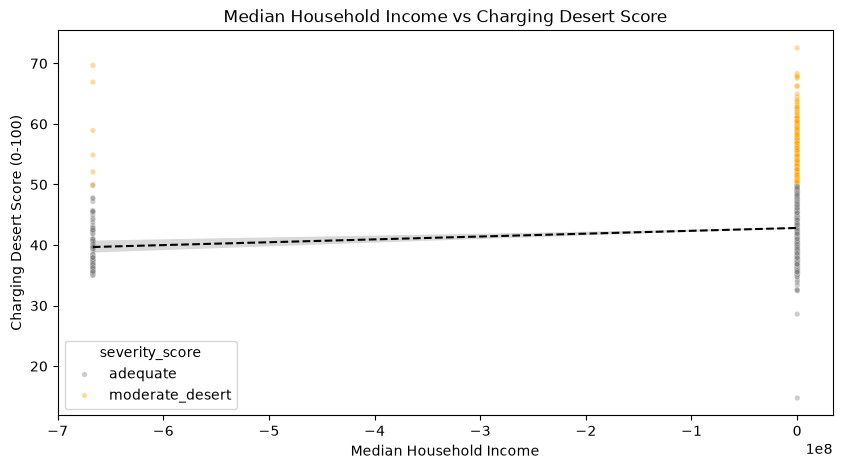

In [21]:
# Compare desert score against median household
plt.figure(figsize=(10,5))

# Filter out tracts where income is missing/null
valid_income = deserts_gdf[deserts_gdf['median_income'].notna()]

# Scatter plot
sns.scatterplot(
    data=valid_income,
    x='median_income',
    y='desert_score',
    hue='severity_score',
    palette={'adequate': 'gray', 'moderate_desert': 'orange', 'severe_desert': 'red'},
    alpha=0.4,
    s=15
)

# Trend line
sns.regplot(
    data=valid_income,
    x='median_income',
    y='desert_score',
    scatter=False,
    color='black',
    line_kws={'linestyle': '--', 'linewidth': 1.5}
)
plt.xlabel("Median Household Income")
plt.ylabel("Charging Desert Score (0-100)")
plt.title("Median Household Income vs Charging Desert Score")
plt.show()


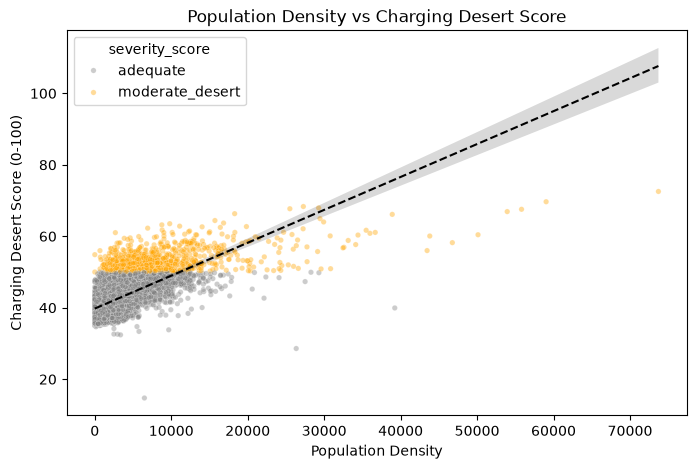

In [25]:
# Compare desert score against population density
plt.figure(figsize=(8,5))

# Filter out where population is missing
valid_pop = deserts_gdf[deserts_gdf['population_density'].notna()]

# Scatter plot 
sns.scatterplot(
    data=valid_pop,
    x='population_density',
    y='desert_score',
    hue='severity_score',
    palette={'adequate': 'gray', 'moderate_desert': 'orange', 'severe_desert': 'red'},
    alpha=0.4,
    s=15
)

# Trend line
sns.regplot(
    data=valid_pop,
    x='population_density',
    y='desert_score',
    scatter=False,
    color='black',
    line_kws={'linestyle': '--', 'linewidth': 1.5}
)
plt.xlabel("Population Density")
plt.ylabel("Charging Desert Score (0-100)")
plt.title("Population Density vs Charging Desert Score")
plt.show()

## Export

In [ ]:
# desert_detection.py already writes this file. To regenerate it, export from the
# full-resolution layer (re-exporting deserts_gdf would simplify it a second time).
from analysis.desert_detection import export_desert_geojson

full_res_gdf = gpd.read_parquet(PROCESSED_DIR / "charging_deserts.parquet")
geojson_path = export_desert_geojson(full_res_gdf)